In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

%matplotlib inline

In [2]:
df = pd.read_csv('../lab-eda-univariate/amz_uk_price_prediction_dataset.csv')

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

In [5]:
crosstab_proportion = crosstab_result.copy()
crosstab_proportion = crosstab_proportion.reset_index()
crosstab_proportion.columns.name = None
crosstab_proportion.columns = crosstab_proportion.columns.astype(str)

In [6]:
crosstab_proportion['proportion_best_seller'] = crosstab_proportion['True'] / (crosstab_proportion['True'] + crosstab_proportion['False'])

In [7]:
crosstab_proportion = crosstab_proportion.sort_values('proportion_best_seller', ascending=False)
crosstab_proportion = crosstab_proportion.reset_index(drop=True)

In [8]:
crosstab_proportion.head(10)

,category,False,True,proportion_best_seller
0,Grocery,9008,556,0.058135
1,Smart Home Security & Lighting,98,6,0.057692
2,Health & Personal Care,9017,552,0.057686
3,Mobile Phone Accessories,248,11,0.042471
4,Power & Hand Tools,8353,306,0.035339
5,"Billiard, Snooker & Pool",241,8,0.032129
6,Pet Supplies,9152,285,0.030200
7,Home Brewing & Wine Making,239,7,0.028455
8,Wind Instruments,243,7,0.028000
9,Mirrors,243,7,0.028000


In [9]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value
#No association between values because chi2 p value is 0

(36540.20270061387, 0.0)

In [10]:
association(crosstab_result, method="cramer")
#Weak association between product category and best seller status

0.1222829439760564

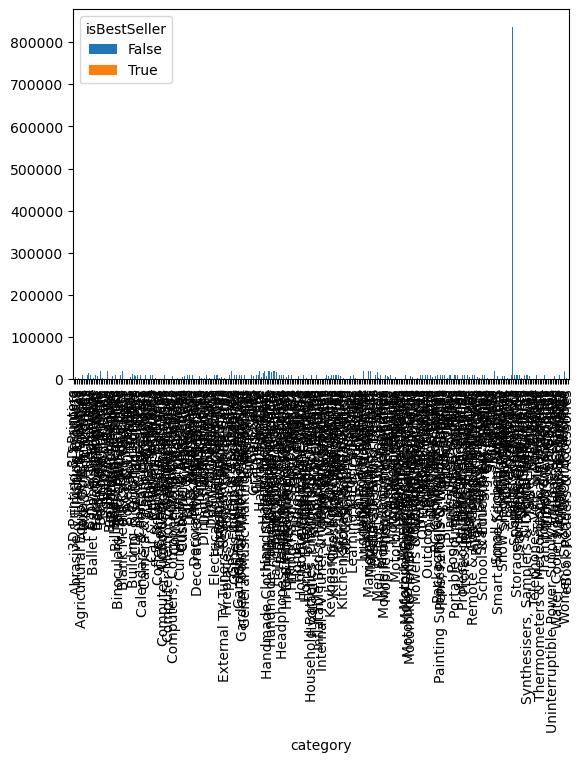

In [11]:
crosstab_result.plot(kind="bar", stacked=True);
#Awful viz, too much categories

In [56]:
def tukeys_test_outliers(data):
    Q1 = data['price'].quantile(0.25)
    Q3 = data['price'].quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    not_outliers = data[(data['price'] > lower_bound) & (data['price'] < upper_bound)]
    outliers = data[(data['price'] < lower_bound) | (data['price'] > upper_bound)]

    return not_outliers, outliers

In [58]:
not_outliers, outliers = tukeys_test_outliers(df)

In [60]:
df.shape

(2443651, 9)

In [62]:
not_outliers.shape

(2115963, 9)

In [64]:
outliers.shape

(327688, 9)

In [66]:
not_outliers.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [68]:
top_20_categories = not_outliers['category'].value_counts().head(20).index.values

In [70]:
top_20_cat_df = not_outliers[not_outliers['category'].isin(top_20_categories)]
top_20_cat_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products


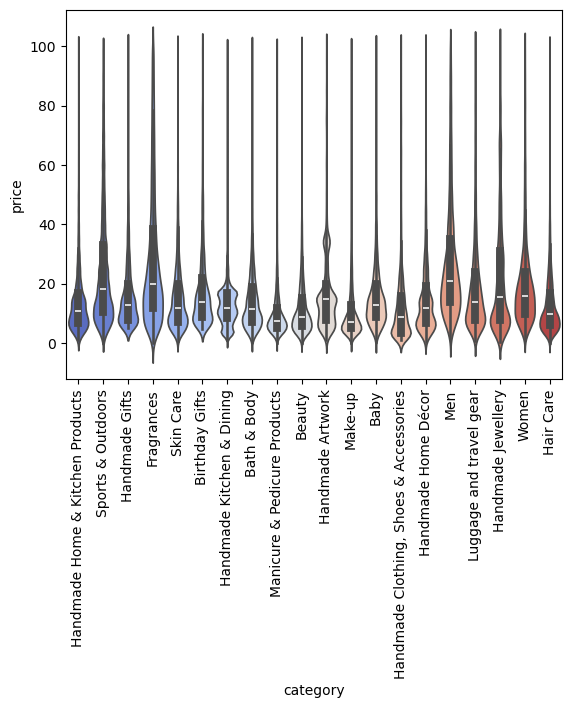

In [78]:
ax = sns.violinplot(data=top_20_cat_df, x='category', y='price', palette="coolwarm", hue='category', legend=False)
ax.tick_params(axis='x', labelrotation=90)

In [92]:
not_outliers.loc[:,['category','price']].groupby('category').agg('median').sort_values(by='price', ascending=False)
#Desktop PCs have highest median price

,price
category,
Desktop PCs,74.00
Boxing Shoes,69.79
Tablets,69.00
Graphics Cards,68.54
Motherboards,67.92
...,...
Adapters,7.05
Make-up,7.00
Signs & Plaques,6.99


In [94]:
top_10_categories = not_outliers['category'].value_counts().head(10).index.values
top_10_cat_df = not_outliers[not_outliers['category'].isin(top_10_categories)]
top_10_cat_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors


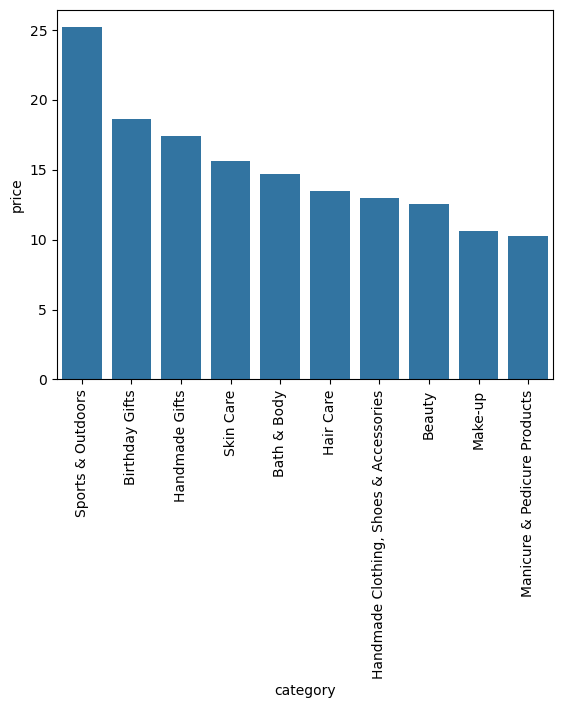

In [104]:
ax = sns.barplot(data = top_10_cat_df.loc[:,['category','price']].groupby('category').agg('mean').sort_values(by='price', ascending=False), x='category', y='price')
ax.tick_params(axis='x', labelrotation=90)

In [106]:
not_outliers.loc[:,['category','price']].groupby('category').agg('mean').sort_values(by='price', ascending=False)
#Motherboards have highest mean price

,price
category,
Motherboards,68.772432
Boxing Shoes,67.417803
Desktop PCs,66.915562
Tablets,66.552971
Graphics Cards,65.103509
...,...
Bedding Accessories,8.835220
Adapters,8.750197
Signs & Plaques,8.210513


Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

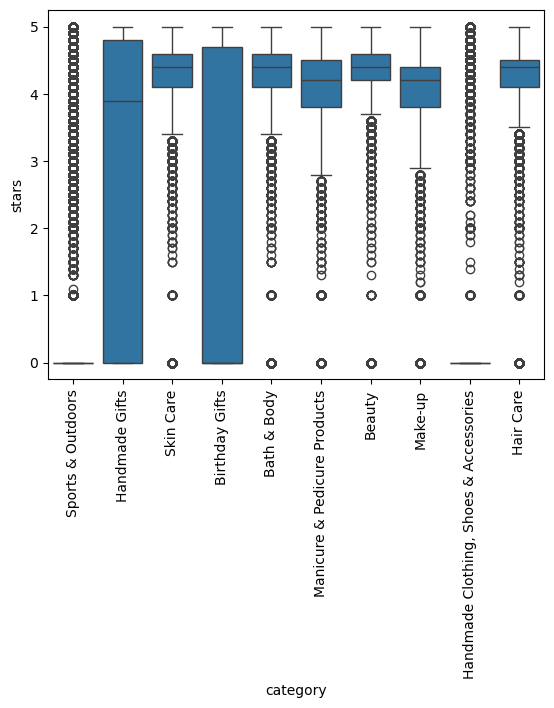

In [114]:
ax = sns.boxplot(data=top_10_cat_df, x='category', y='stars')
ax.tick_params(axis='x', labelrotation=90)

In [116]:
not_outliers.loc[:,['category','stars']].groupby('category').agg('median').sort_values(by='stars', ascending=False)
#Computer Memory has highest median ratings

,stars
category,
Computer Memory,4.7
Building & Construction Toys,4.6
Office Paper Products,4.6
Luxury Food & Drink,4.6
Kids' Play Figures,4.6
...,...
Hockey Shoes,0.0
Hi-Fi Receivers & Separates,0.0
Handmade Kitchen & Dining,0.0


Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [122]:
correlation = not_outliers['stars'].corr(df['price'])
correlation

-0.0776729987818137

In [123]:
correlation = not_outliers['stars'].corr(df['price'], method='spearman')
correlation

-0.06679697280768314

We can't see a significant correlation between stars and price

<Axes: xlabel='stars', ylabel='price'>

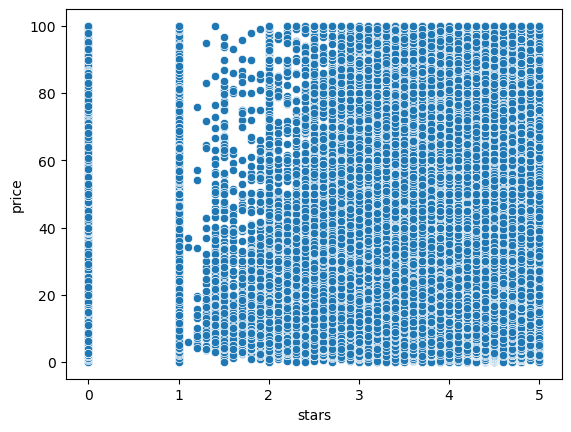

In [131]:
sns.scatterplot(data=not_outliers, x='stars', y='price');
#No patterns

In [138]:
potential_categorical_from_numerical = not_outliers.select_dtypes("number").loc[:, not_outliers.select_dtypes("number").nunique() < 20]
df_numerical = not_outliers.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

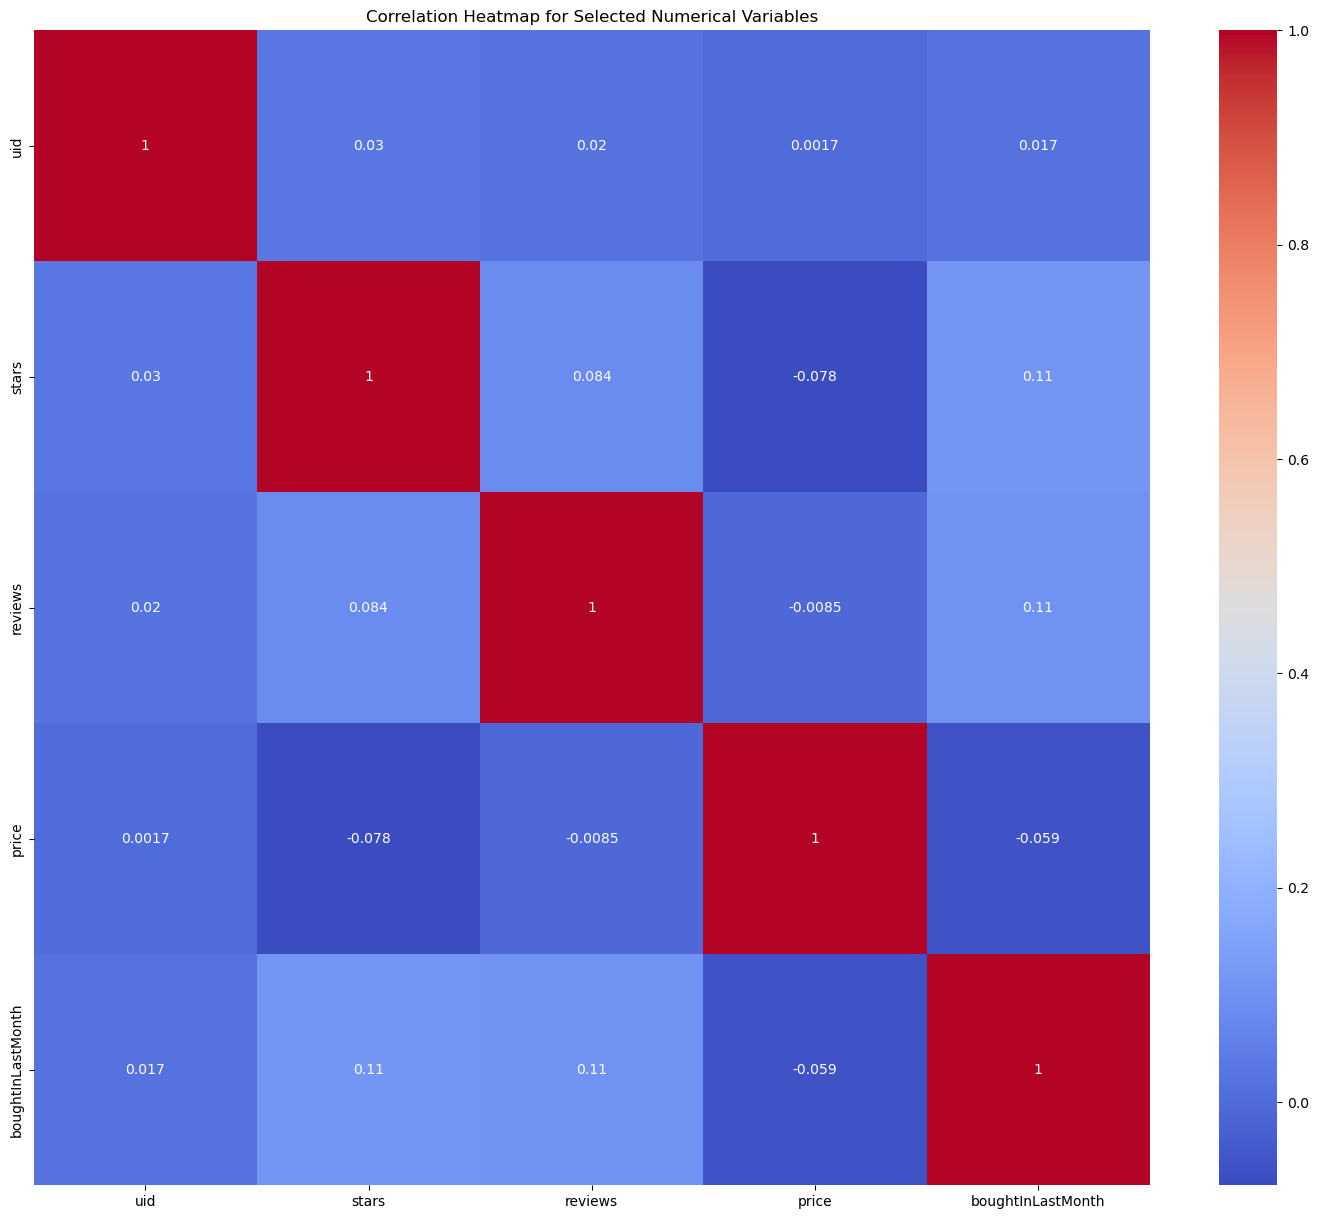

In [140]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()
#No real correlation

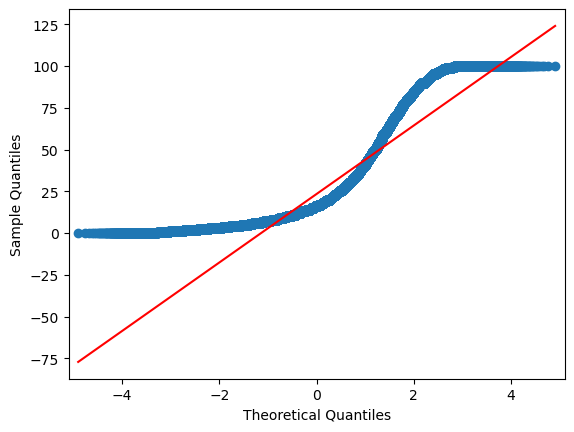

In [143]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(not_outliers['price'], line='s');
#Does not follow a normal distribution